# 5. Aprendizaje No Supervisado
Objetivo: descubrir perfiles de estudiantes y estructuras presentes en los datos sin usar la etiqueta objetivo. Combinamos PCA (reducción de dimensionalidad) con K-Means (clustering) sobre las variables numéricas, que son las que mostraron mayor poder predictivo en los apartados anteriores.

### Imports y carga de datos

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv('../rendimiento_estudiantes.csv', sep=';')

### Selección de variables
Se usan únicamente las variables numéricas: rendimiento de ambos semestres, nota de admisión, edad, etc. Excluimos las categóricas (ocupación padres, nacionalidad...) porque en alta dimensionalidad perjudican el clustering al introducir ruido (se crearía una columna por cada clase de cada una, añadiendo mucha complejidad innecesaria).

In [62]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

print(f'Variables numéricas totales: {len(num_cols)}')

print('\nColumnas:')
for c in num_cols:
    print(c)

Variables numéricas totales: 19

Columnas:
orden_solicitud
nota_cualificacion_previa
nota_admision
edad_al_matricularse
asignaturas_1sem_convalidadas
asignaturas_1sem_matriculadas
asignaturas_1sem_evaluadas
asignaturas_1sem_aprobadas
nota_media_1sem
asignaturas_1sem_sin_evaluacion
asignaturas_2sem_convalidadas
asignaturas_2sem_matriculadas
asignaturas_2sem_evaluadas
asignaturas_2sem_aprobadas
nota_media_2sem
asignaturas_2sem_sin_evaluacion
tasa_desempleo
tasa_inflacion
pib


### Escalado
Escalamos todas las variables a media 0 y desviación estándar 1. PCA y K-Means son sensibles a las magnitudes: sin escalar, variables como nota_admision (0-200) dominarían sobre, por ejemplo, edad (17-70).

In [63]:
X = df[num_cols].dropna()
y_real = df.loc[X.index, 'objetivo']  # etiqueta real, solo para validar al final, no se usará en el aprendizaje

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### PCA: Reducción de dimensionalidad

PCA toma variables correladas y las combina en nuevas variables (componentes principales) ortogonales entre sí, ordenadas de mayor a menor varianza explicada. Es decir, el primer componente captura la dirección de máxima variabilidad, el segundo la siguiente, etc.

Se hace antes del clustering porque con muchas variables, las distancias que usa K-Means se vuelven muy parecidas (maldición de la dimensionalidad). PCA reduce el espacio a las dimensiones más informativas.

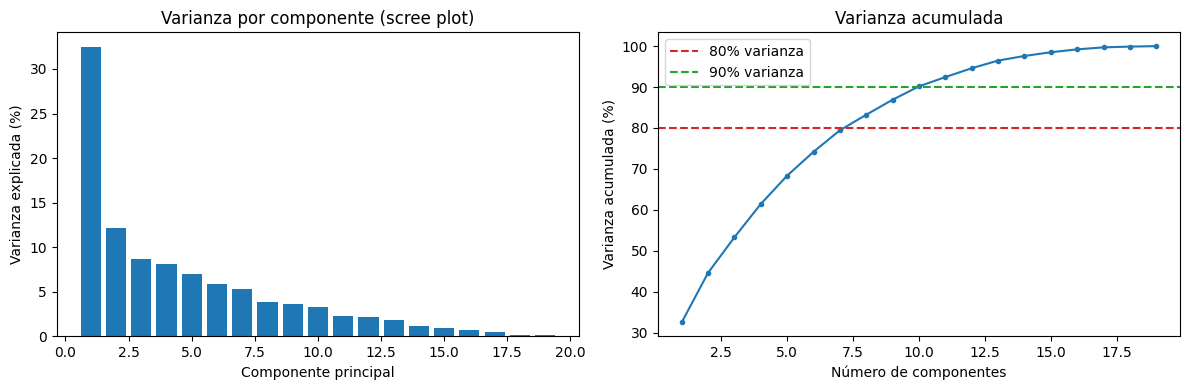

Diferentes umbrales:
50.0% varianza explicada con 3 componentes
70.0% varianza explicada con 6 componentes
80.0% varianza explicada con 8 componentes
90.0% varianza explicada con 10 componentes
95.0% varianza explicada con 13 componentes
99.0% varianza explicada con 16 componentes
99.9% varianza explicada con 19 componentes


In [64]:
# PCA completo para ver la varianza acumulada
pca_full = PCA()
pca_full.fit(X_scaled)

varianza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Varianza por componente
n = len(pca_full.explained_variance_ratio_)
axes[0].bar(range(1, n+1), pca_full.explained_variance_ratio_ * 100, color='tab:blue')
axes[0].set_xlabel('Componente principal')
axes[0].set_ylabel('Varianza explicada (%)')
axes[0].set_title('Varianza por componente (scree plot)')

# Varianza acumulada
n = len(varianza_acumulada)
axes[1].plot(range(1, n+1), varianza_acumulada * 100, marker='o', markersize=3, color='tab:blue')
axes[1].axhline(y=80, color='tab:red', linestyle='--', label='80% varianza')
axes[1].axhline(y=90, color='tab:green', linestyle='--', label='90% varianza')
axes[1].set_xlabel('Número de componentes')
axes[1].set_ylabel('Varianza acumulada (%)')
axes[1].set_title('Varianza acumulada')
axes[1].legend()

plt.tight_layout()
plt.show()

# Umbrales
print('Diferentes umbrales:')
for umbral in [0.50, 0.70, 0.80, 0.90, 0.95, 0.99, 0.999]:
    n = np.argmax(varianza_acumulada >= umbral) + 1
    print(f'{umbral*100}% varianza explicada con {n} componentes')

> El scree plot muestra cuánta información aporta cada componente. A ojo, se puede ver que el 'codo', es decir, punto a partir del cual añadir otro componente no añade mucha información, está alrededor de 2. Los componentes PC1 y PC2 explican un 45% de la varianza, demasiado bajo para representar la estructura de los datos. Se escogen 8 componentes, el mínimo para superar el 80% de la varianza (explican un 83,2%).

In [65]:
# Aplicamos PCA con los componentes necesarios para 80% de varianza
n_componentes = np.argmax(varianza_acumulada >= 0.80) + 1
print(f'Usando {n_componentes} componentes principales (~80% varianza)')

pca = PCA(n_components=n_componentes, random_state=0)
X_pca = pca.fit_transform(X_scaled)

print(f'Dimensiones originales: {X_scaled.shape[1]}')
print(f'Dimensiones reducidas:  {X_pca.shape[1]}')
print(f'Varianza explicada total: {pca.explained_variance_ratio_.sum():.3f}')

Usando 8 componentes principales (~80% varianza)
Dimensiones originales: 19
Dimensiones reducidas:  8
Varianza explicada total: 0.832


### Elección del número de clusters: Método del codo + Silhouette
K-Means requiere elegir el número de clusters k de antemano. Se usan dos métricas de validación:

- **Inercia (método del codo):** suma de distancias al cuadrado de cada punto a su centroide. Decrece al aumentar k; buscamos el 'codo' donde la mejora se estabiliza.
- **Silhouette score:** mide qué tan bien separados están los clusters (valores entre -1 y 1, más alto es mejor). Combina cohesión interna y separación entre clusters.

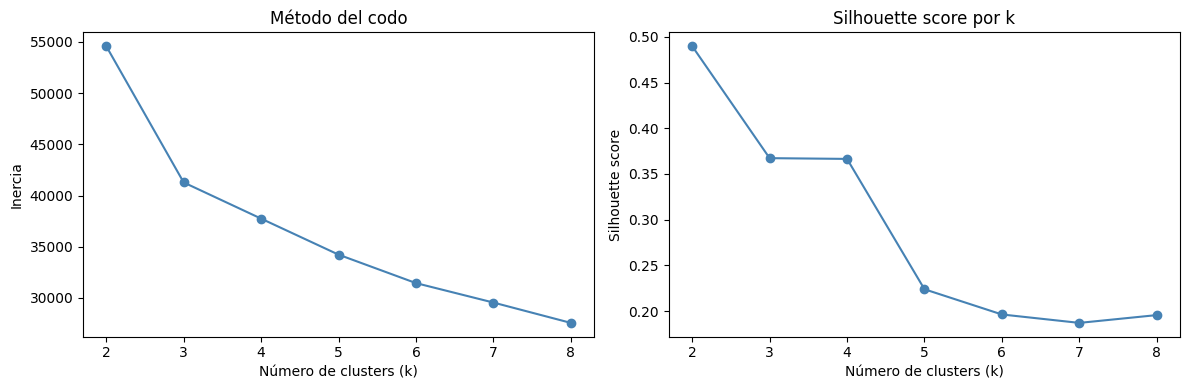

Mejor k según Silhouette: 2 (score=0.490)


In [66]:
inercias = []
silhouettes = []
rango_k = range(2, 9)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = km.fit_predict(X_pca)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(rango_k, inercias, marker='o', color='steelblue')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo')

axes[1].plot(rango_k, silhouettes, marker='o', color='steelblue')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score por k')

plt.tight_layout()
plt.show()

mejor_k = list(rango_k)[np.argmax(silhouettes)]
print(f'Mejor k según Silhouette: {mejor_k} (score={max(silhouettes):.3f})')

> El codo está en k=3 (según las inercias), y Silhouette indica que el mejor es k=2. Se conservan ambos y se comparan. k=3 coincide con el número de clases reales de la variable objetivo (Abandono / Matriculado / Graduado).

### Clustering con K-Means
Aplicamos K-Means con k=2 y k=3 para comparar. K-Means asigna cada punto al centroide más cercano e itera hasta convergencia.

In [67]:
# Entrenamos con el k óptimo según Silhouette (k=2)
km_2 = KMeans(n_clusters=mejor_k, random_state=0, n_init=10)
clusters_2 = km_2.fit_predict(X_pca)

# También con k=3 por el codo y por correspondencia con las clases reales
km_3 = KMeans(n_clusters=3, random_state=0, n_init=10)
clusters_3 = km_3.fit_predict(X_pca)

print(f'Clustering k={mejor_k}: {np.unique(clusters_2, return_counts=True)}')
print(f'Clustering k=3:  {np.unique(clusters_3, return_counts=True)}')

Clustering k=2: (array([0, 1]), array([ 285, 4139], dtype=int64))
Clustering k=3:  (array([0, 1, 2]), array([ 842, 3316,  266], dtype=int64))


### Visualización: Proyección en PC1-PC2
Visualización de los clusters proyectando sobre los dos primeros componentes principales. Esto es una simplificación (solo muestra parte de la varianza), pero permite interpretar visualmente la separación entre grupos.

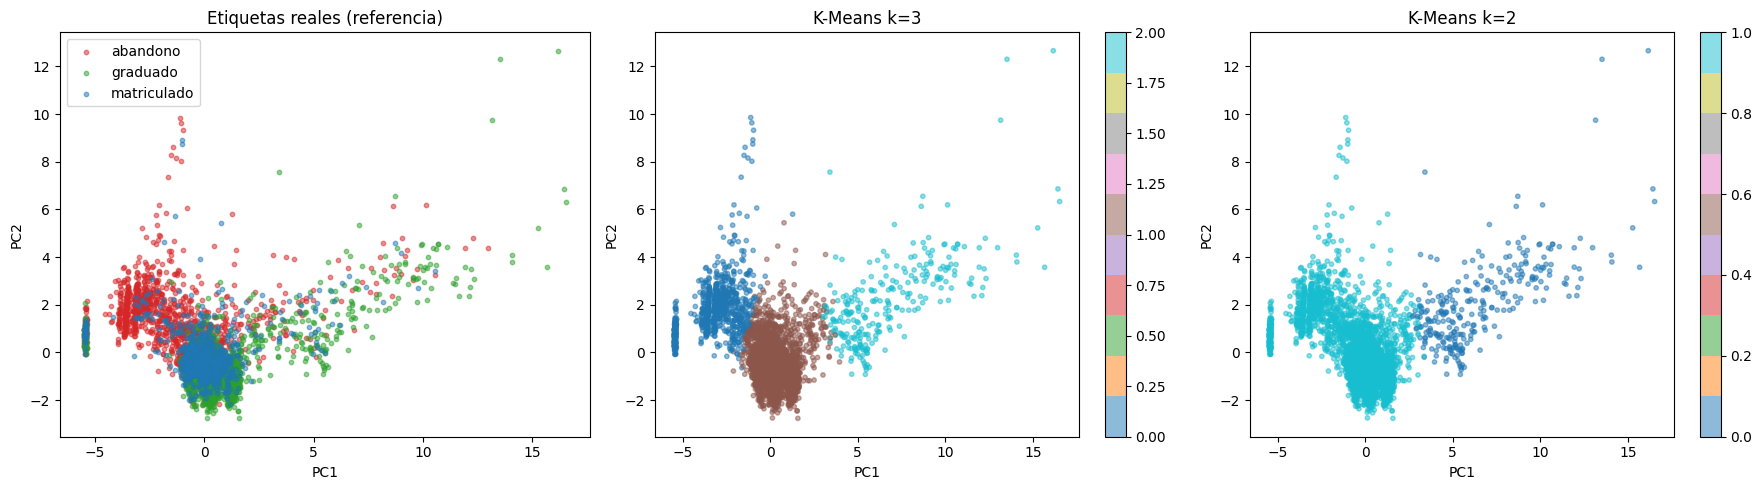

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter con etiquetas reales
colores_reales = {'abandono': 'tab:red', 'graduado': 'tab:green', 'matriculado': 'tab:blue'}
for clase, color in colores_reales.items():
    mask = y_real == clase
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],c=color, label=clase, alpha=0.5, s=10)
axes[0].set_title('Etiquetas reales (referencia)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

# Clusters con k=3
scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_3, cmap='tab10', alpha=0.5, s=10)
axes[1].set_title('K-Means k=3')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
plt.colorbar(scatter, ax=axes[1])

# Clusters con k=2
scatter2 = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_2, cmap='tab10', alpha=0.5, s=10)
axes[2].set_title(f'K-Means k={mejor_k}')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
plt.colorbar(scatter2, ax=axes[2])

plt.tight_layout()
plt.show()

> En la proyección PC1-PC2, los clusters de K-Means forman regiones bastante bien delimitadas, mientras que las etiquetas reales se solapan mucho, sobre todo 'graduado' y 'matriculado'. Es decir, la estructura que encuentra K-Means no coincide con las clases reales. Esta proyección solo recoge el 45% de la varianza; el clustering se hizo en el espacio de 8 componentes, donde el Silhouette para k=3 es 0.37 (separación moderada).

### Interpretación de los clusters (k=3)
Analizamos las características medias de cada cluster para entender qué tipo de estudiante representa cada grupo. Comparamos con la distribución real de la variable objetivo.

In [70]:
df_clusters = X.copy()
df_clusters['cluster'] = clusters_3
df_clusters['objetivo_real'] = y_real.values

# Perfil medio de cada cluster
print('- Perfil medio por cluster -')
print(df_clusters.groupby('cluster')[num_cols].mean().round(2).T.to_string())

- Perfil medio por cluster -
cluster                               0       1       2
orden_solicitud                    1.56    1.82    1.14
nota_cualificacion_previa        132.80  132.61  132.01
nota_admision                    126.83  126.80  129.62
edad_al_matricularse              25.99   22.13   28.72
asignaturas_1sem_convalidadas      0.04    0.23    8.86
asignaturas_1sem_matriculadas      4.35    6.19   13.39
asignaturas_1sem_evaluadas         4.47    8.59   16.81
asignaturas_1sem_aprobadas         0.33    5.25   11.83
nota_media_1sem                    1.80   12.72   12.67
asignaturas_1sem_sin_evaluacion    0.24    0.09    0.44
asignaturas_2sem_convalidadas      0.01    0.17    6.89
asignaturas_2sem_matriculadas      4.41    6.26   11.66
asignaturas_2sem_evaluadas         3.64    8.66   14.69
asignaturas_2sem_aprobadas         0.08    5.09   10.11
nota_media_2sem                    0.56   12.49   12.69
asignaturas_2sem_sin_evaluacion    0.29    0.10    0.30
tasa_desempleo     

> Con esto se puede deducir que el cluster 0 son estudiantes con bajo rendimiento (probablemente abandono), y los clusters 1 y 2 son estudiantes con alto rendimiento (probablemente matriculados/graduados). Los estudiantes del cluster 2 tienen más asignaturas que los del cluster 1. 

- Distribución de objetivo real por cluster -
objetivo_real  abandono  graduado  matriculado
cluster                                       
0                  82.2       9.0          8.8
1                  20.2      59.2         20.6
2                  22.2      64.3         13.5



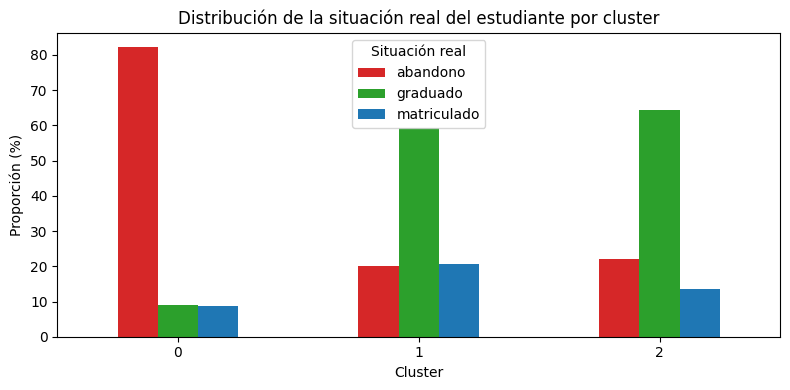

In [71]:
# Distribución de la variable objetivo real dentro de cada cluster
print('- Distribución de objetivo real por cluster -')
tabla = pd.crosstab(df_clusters['cluster'], df_clusters['objetivo_real'], normalize='index') * 100
print(tabla.round(1).to_string())
print()

# Visualización
tabla.plot(kind='bar', figsize=(8, 4), color=['tab:red', 'tab:green', 'tab:blue'])
plt.title('Distribución de la situación real del estudiante por cluster')
plt.xlabel('Cluster')
plt.ylabel('Proporción (%)')
plt.xticks(rotation=0)
plt.legend(title='Situación real')
plt.tight_layout()
plt.show()

> La gráfica valida bien lo que se esperaba. El cluster 0 es el más diferenciado: un 82% de sus estudiantes abandona, aunque agrupa solo a algo menos de la mitad (~49%, 692 de 1.421) de todos los que abandonan. Esto indica que un rendimiento casi nulo está muy asociado al abandono, pero no que todos los abandonos tengan ese perfil.

> El cluster 1 tiene un 59% de graduados, con 'abandono' y 'matriculado' casi a partes iguales en el resto, y el cluster 2 es parecido, con un 64% de graduados. Esto refleja el parecido en el perfil de un estudiante que sigue matriculado y uno que se gradúa, con el añadido de lo poco poblada que está la clase 'matriculado', algo que se lleva viendo durante todo el proyecto.

> Lo más probable es que los clusters 1 y 2 hagan una distinción entre estudiantes recién llegados de bachillerato y estudiantes adultos, mucho más distintiva (diferencias en edad, asignaturas que cursan, asignaturas convalidadas, etc.) que 'graduado' vs. 'matriculado'.

### Contribución de variables a los componentes principales
Analizamos qué variables tienen mayor peso en PC1 y PC2 para poder interpretar qué dimensiones captura cada componente.

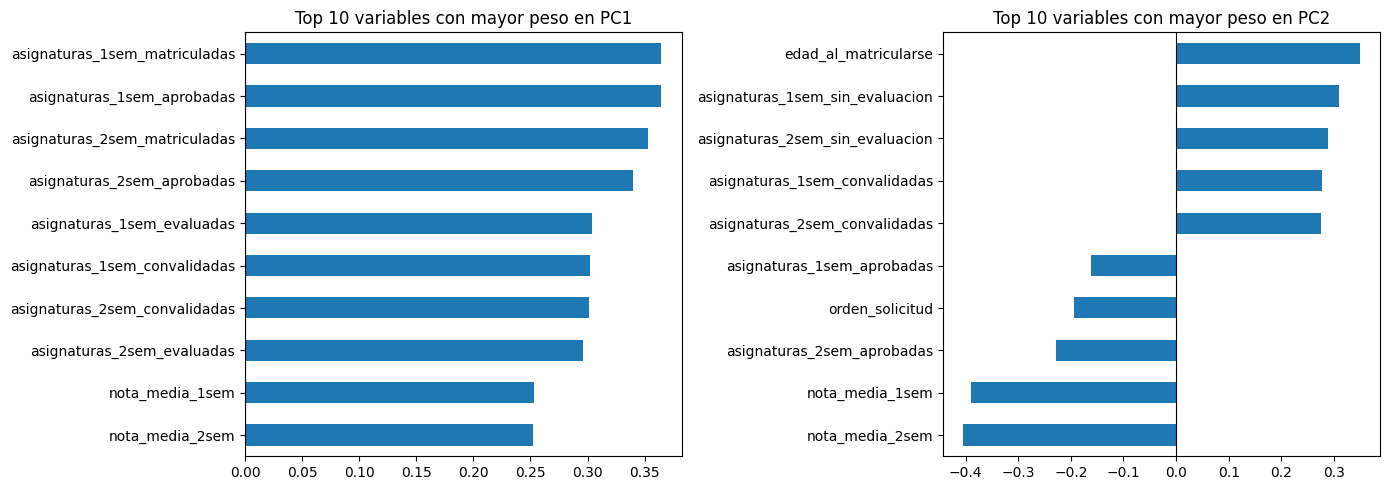

In [72]:
loadings = pd.DataFrame(pca.components_[:2].T, index=num_cols, columns=['PC1', 'PC2'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, pc in enumerate(['PC1', 'PC2']):
    top = loadings[pc].abs().sort_values(ascending=False).head(10)
    loadings.loc[top.index, pc].sort_values().plot(kind='barh', ax=axes[i], color='tab:blue')
    axes[i].set_title(f'Top 10 variables con mayor peso en {pc}')
    axes[i].axvline(x=0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

> PC1 y PC2 juntos explican la estructura principal de los datos. PC1 captura el nivel académico del alumno y PC2 distingue entre dos perfiles: joven, buen rendimiento en notas; y mayor, con asignaturas convalidadas y asignaturas sin evaluación. Esto es coherente con los tres clusters identificados, con lo comentado anteriormente de los clusters 1 y 2.